In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json

# Only install packages that need to be added, without forcing a NumPy downgrade
!pip install -q --upgrade sentence-transformers chromadb kagglehub "pyarrow==16.1.0" "datasets<4"
!pip install -q --upgrade sentence-transformers chromadb kagglehub "pyarrow==14.0.1" "datasets<4"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.16.2 requires torch==2.1.2, but you have torch 2.15.0 which is incompatible.
deepnote-toolkit 2.9.0 requires fsspec>=2026.6.0, but you have fsspec 2025.3.0 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.16.2 requires torch==2.1.2, but you have torch 2.15.0 which is incompatible.
deepnote-toolkit 2.9.0 requires fsspec>=2026.6.0, but you have fsspec 2024.3.1 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
!pip install -q --upgrade "numpy>=2.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pandas 2.1.4 requires numpy<2,>=1.23.2; python_version == "3.11", but you have numpy 2.4.6 which is incompatible.
scikit-learn 1.3.2 requires numpy<2.0,>=1.17.3, but you have numpy 2.4.6 which is incompatible.
scipy 1.11.4 requires numpy<1.28.0,>=1.21.6, but you have numpy 2.4.6 which is incompatible.
thinc 8.2.5 requires numpy<2.0.0,>=1.19.0; python_version >= "3.9", but you have numpy 2.4.6 which is incompatible.
torchvision 0.16.2 requires torch==2.1.2, but you have torch 2.15.0 which is incompatible.
deepnote-toolkit 2.9.0 requires fsspec>=2026.6.0, but you have fsspec 2024.3.1 which is incompatible.
deepnote-toolkit 2.9.0 requires numpy<2,>=1.24; python_version == "3.11", but you have numpy 2.4.6 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip inst

## TODO BEFORE NEXT WEEK

- Import your dataset 

- Do some basic EDA

- Get some kind of retrieval stack started \-\> things you'll need to do:

  - pick some kind of embedding model \(some RoBERTa variant is prob fine\) \(Chose: all\-distilroberta\-v1\)

  - embed the corpus and store in some kind of vector db \(I recommend chroma\)

  - get similarity search set up

## Some Things You May Want to Learn

  - Necessary technologies: Difference between different embedding models, perhaps some fine tuned ones for finance, chroma/faiss/pgvector or any kind of vectordb

## Stretch Goals \(For Next Week\)

- Some kind of reranking

- Hybrid keyword search 

Possible DataSet Options: 

https://huggingface\.co/datasets/Brianferrell787/financial\-news\-multisource

https://www\.kaggle\.com/datasets/rdolphin/financial\-news\-with\-ticker\-level\-sentiment 

https://www\.kaggle\.com/datasets/vladtasca/fomc\-meeting\-statements\-and\-minutes

https://huggingface\.co/datasets/luckycat37/financial\-news\-dataset

Sentiment analysis: https://www\.kaggle\.com/code/khotijahs1/nlp\-financial\-news\-sentiment\-analysis

Possible vector DB solutions
ChromaDB \- free and open source

# Start of Code 

In [3]:

!pip install kagglehub


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [4]:

!pip install chromadb sentence-transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 47.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.16.2 requires torch==2.1.2, but you have torch 2.15.0 which is incompatible.
deepnote-toolkit 2.9.0 requires fsspec>=2026.6.0, but you have fsspec 2024.3.1 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [5]:
import os
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("rdolphin/financial-news-with-ticker-level-sentiment")
print(path)
print(os.listdir(path))

df = pd.read_json(os.path.join(path, "polygon_news_sample.json"))


/root/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 2.16M/2.16M [00:00<00:00, 3.63MB/s]Extracting files...

/root/.cache/kagglehub/datasets/rdolphin/financial-news-with-ticker-level-sentiment/versions/1
['polygon_news_sample.json']


In [6]:
rows, cols = df.shape
print(f"Dataset has {rows} records and {cols} features")
df.info()

print(df.isnull().sum())
print("Duplicated titles:", df.duplicated(subset="title").sum())

print(df[["title", "description"]].head(3))

print(df["description"].str.len().describe())

Dataset has 5548 records and 12 features
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5548 entries, 0 to 5547
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   article_url    5548 non-null   object
 1   author         5548 non-null   object
 2   description    5548 non-null   object
 3   id             5548 non-null   object
 4   image_url      5498 non-null   object
 5   amp_url        61 non-null     object
 6   keywords       5548 non-null   object
 7   published_utc  5548 non-null   object
 8   publisher      5548 non-null   object
 9   tickers        5548 non-null   object
 10  insights       5548 non-null   object
 11  title          5548 non-null   object
dtypes: object(12)
memory usage: 520.3+ KB
article_url         0
author              0
description         0
id                  0
image_url          50
amp_url          5487
keywords            0
published_utc       0
publisher           0
tickers  

In [7]:
# Harshan - this block is for cleanign the data  (dropping missing columns) , removing duplicates, converting published dates to datetimes

df_clean = df.copy()

df_clean = df_clean.drop(columns=["amp_url", "image_url"])


df_clean = df_clean.dropna(subset=["title", "description"])


df_clean = df_clean.drop_duplicates(subset="title", keep="first")


df_clean["published_utc"] = pd.to_datetime(
    df_clean["published_utc"], errors="coerce", utc=True
)
df_clean = df_clean.dropna(subset=["published_utc"])

print("rows after cleaning:", len(df_clean))

# Chroma metadata only accepts plain values: keep just the publisher name
df_clean["publisher"] = df_clean["publisher"].apply(lambda p: p.get("name") if isinstance(p, dict) else p)

rows after cleaning: 5472


In [8]:


# from sentence_transformers import SentenceTransformer

# model = SentenceTransformer("sentence-transformers/all-distilroberta-v1")
# texts = df_clean["text"].tolist()
# embeddings = model.encode(texts[:3])
# print(embeddings.shape)  # (3, 768)

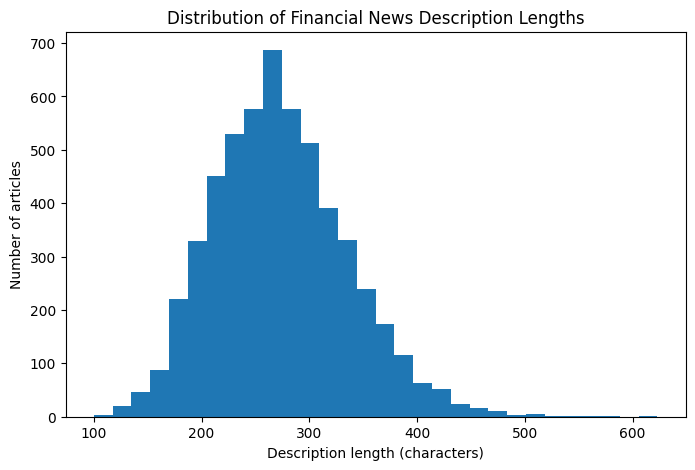

In [9]:

# Calculate the character length of each description.
description_lengths = df_clean["description"].str.len()

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(description_lengths, bins=30)
plt.xlabel("Description length (characters)")
plt.ylabel("Number of articles")
plt.title("Distribution of Financial News Description Lengths")
plt.show()

/tmp/ipykernel_221/2930192786.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_clean["month"] = df_clean["published_utc"].dt.to_period("M")


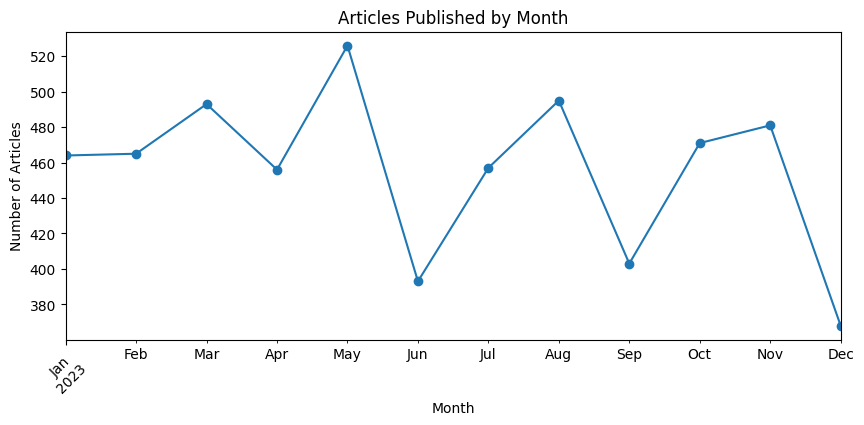

In [10]:
#Harshan, this is  line graph ( number of articles published per month)
df_clean["month"] = df_clean["published_utc"].dt.to_period("M")

df_clean.groupby("month").size().plot(
    kind="line", figsize=(10, 4), marker="o"
)
plt.title("Articles Published by Month")
plt.xlabel("Month")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()

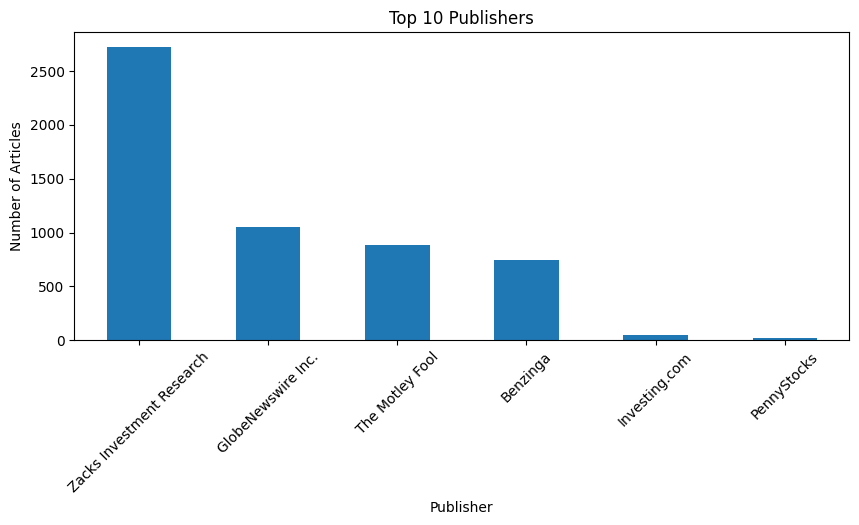

In [11]:
#bar chart: top 10 publishers by number of articles
top_publishers = df_clean["publisher"].value_counts().head(10)

top_publishers.plot(kind="bar", figsize=(10, 4))
plt.title("Top 10 Publishers")
plt.xlabel("Publisher")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()

In [12]:

#Combining title and text to 1 
df_clean["text"] = (
    df_clean["title"].fillna("") + " " + df_clean["description"].fillna("")
)
texts = df_clean["text"].tolist()
print("Number of texts:", len(texts))

Number of texts: 5472


In [13]:
#Embed every article with all-distilroberta / HAVING problem
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("all-distilroberta-v1")

embeddings = model.encode(
    texts, batch_size = 64, show_progress_bar=True, convert_to_numpy=True
)
print(embeddings.shape)   

/root/venv/lib/python3.11/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /root/venv/lib/python3.11/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


ImportError: pyarrow requires NumPy 2.0 or newer, found 1.26.4

In [14]:
# Storing embeddings + metadata in a Chroma vector database
import chromadb

client = chromadb.PersistentClient(path="./chroma_db")

collection = client.get_or_create_collection(
    name="financial_news",
    metadata={"hnsw:space": "cosine"}
)

# Prepare metadata first.
metadatas = []

for _, row in df_clean.iterrows():
    metadatas.append({
        "title": row["title"],
        "publisher": row["publisher"],
        "published_utc": str(row["published_utc"]),
        "article_url": row["article_url"],
    })

# Upload articles in smaller batches.
batch_size = 1000
n_docs = len(texts)

assert (
    len(df_clean) == n_docs == len(embeddings) == len(metadatas)
), "Articles, embeddings, and metadata have different lengths."

for start in range(0, n_docs, batch_size):
    end = min(start + batch_size, n_docs)

    collection.upsert(
        ids=[str(i) for i in range(start, end)],
        documents=texts[start:end],
        embeddings=embeddings[start:end].tolist(),
        metadatas=metadatas[start:end]
    )

    print(f"Uploaded {end} of {n_docs} articles")

print("Docs in collection:", collection.count())

assert collection.count() == n_docs, (
    "Collection count does not match the current dataset."
)

Uploaded 1000 of 5472 articles
Uploaded 2000 of 5472 articles
Uploaded 3000 of 5472 articles
Uploaded 4000 of 5472 articles
Uploaded 5000 of 5472 articles
Uploaded 5472 of 5472 articles
Docs in collection: 5472


In [15]:
#Harshan, Sample Test Embed sample query and get 5 most similar articles

1\) Evaluation method: one option is to ask a strong model like gpt5 to review the top 50 by similarity score and rank the top 5\. take a random sample of 50 articles and write questions for each one for a recall evaluation\. \(Everyone\)

2\) better retrieval methods \- basic retrieval \(top k similarity score\), keywords \+ similarity, top k \+ model reranking \(Ethan\)

3\) evaluate on all ur datasets and pick the best one \(Angelina and Varun\)

4\) get some kind of frontend \(gradio interface minimum, webapp would be nice\) where someone can type in a real question and get a response\. \(Daivik\)

5\) integrate with real news sources so that it can pull information live \(would have to store in a real db with links and vectors n such\) \(Daivik\)

In [16]:



# Angelina Evaluation Harness

# Model based bench

model_bench = [
    {
        "question": "What news is there about Tesla?",
        "relevant_titles": [
            "Tesla Stock Skids On Recall Notice For Full Self-Driving Collision Potential: What You Need To Know",
            "Tesla's Energy Business: Faster-Growing and Now More Profitable Than Its Auto Business",
            "'Order Boost' Coming For All Tesla EVs In December, Says Analyst: What's Behind The Optimism?"
        ]
    },
    {
        "question": "What news is there about AI stocks?",
        "relevant_titles": [
            "What Nvidia, Intel, Google, and Tesla Stock Investors Should Know About Recent AI Updates",
            "Microsoft AI Announcement Drives Stock Higher: How Copilot Will Rollout",
            "NVIDIA Introduces Generative AI Foundry Service on Microsoft Azure for Enterprises and Startups Worldwide"
        ]
    },
    {
        "question": "Which companies beat earnings estimates?",
        "relevant_titles": [
            "Sprinkler (CXM) Q3 Earnings and Revenues Top Estimates",
            "AutoZone (AZO) Q1 Earnings & Revenues Surpass Estimates",
            "Culp's (CULP) Q2 Earnings & Revenues Beat Estimates, Stock Up"
        ]
    },
    {
        "question": "Which companies are raising their dividends?",
        "relevant_titles": [
            "Dividend Watch: 3 Companies Boosting Payouts",
            "3 Top-Notch Dividend Stocks That Just Raised Their Payouts to Record Highs",
            "5 Stocks With Recent Dividend Hike for a Stable Portfolio"
        ]
    },
    {
        "question": "Which stocks were upgraded or downgraded by analysts?",
        "relevant_titles": [
            "Benzinga's Top Ratings Upgrades, Downgrades For October 10, 2023",
            "Benzinga's Top Ratings Upgrades, Downgrades For September 14, 2023",
            "Benzinga's Top Ratings Upgrades, Downgrades For September 11, 2023"
        ]
    },
    {
        "question": "What news is there about defense companies?",
        "relevant_titles": [
            "3 Defense Equipment Stocks to Buy as New Acquisitions Raise Hopes",
            "Lockheed (LMT) Wins $842M Deal to Support F-35 Jet Program",
            "Raytheon (RTX) Wins $1.2B Deal for PATRIOT Missile System"
        ]
    },
    {
        "question": "What news is there about oil and energy companies?",
        "relevant_titles": [
            "Why Occidental Petroleum, Devon Energy, and Marathon Oil Stocks Popped Today",
            "Why ExxonMobil and Chevron Stocks Were Gushers Today",
            "BP to Proceed With Clean Energy Plan, Reduce Oil & Gas Output"
        ]
    },
    {
        "question": "What news is there about drug and biotech companies?",
        "relevant_titles": [
            "Biotech Stock Roundup: BMY Grabs MRTX, AKRO Down on Study Data, ALNY Faces Setback",
            "Biotech Stock Roundup: BLUE Announces Q4 Results, ONCT, ASND & RNA Fall on Updates",
            "Bristol Myers Squibb's Mega $8.4B Oncology Bet - Secures Exclusive License With SystImmune"
        ]
    },
    {
        "question": "What news is there about the Fed and interest rates?",
        "relevant_titles": [
            "Fed Meeting Live Updates: 10 Takeaways From May FOMC Meeting & Statement",
            "S&P 500 Makes Weekly Gain As Fed Pauses For First Time In 15 Months; AMD Disappoints With AI Chip Launch; Adobe Beats All Expectations",
            "November Rally Lights Up Stock Market As Speculation Grows Over Potential Fed Rate Cuts: The Week In The Markets"
        ]
    },
    {
        "question": "What are the best growth stocks to buy?",
        "relevant_titles": [
            "Best Growth Stocks to Buy for December 15th",
            "Best Growth Stocks to Buy for November 15th",
            "Best Growth Stocks to Buy for August 22nd"
        ]
    },

    # Varun Bommaji
    {
        "question": "What are the latest developments in Federal Reserve interest rate policy, and how are they affecting financial markets?",
        "relevant_titles": []
    },
    {
        "question": "Which companies have recently reported earnings that significantly exceeded or fell short of analyst expectations?",
        "relevant_titles": []
    },
    {
        "question": "What news suggests that inflation is accelerating or slowing down in the United States?",
        "relevant_titles": []
    },
    {
        "question": "What recent developments indicate increasing financial instability in the banking sector?",
        "relevant_titles": []
    },
    {
        "question": "How are developments in artificial intelligence affecting major technology companies and their stock prices?",
        "relevant_titles": []
    },
    {
        "question": "What factors are contributing to recent increases or decreases in oil prices?",
        "relevant_titles": []
    },
    {
        "question": "Which companies have announced mergers, acquisitions, or major investment deals?",
        "relevant_titles": []
    },
    {
        "question": "What news indicates that the U.S. labor market is strengthening or weakening?",
        "relevant_titles": []
    },
    {
        "question": "What developments involving tariffs, sanctions, or international trade are affecting global markets?",
        "relevant_titles": []
    },
    {
        "question": "What recent news suggests that the housing market is cooling or becoming more competitive?",
        "relevant_titles": []
    },

    # Angelina additional new model-based questions
    {
        "question": "What news is there about cybersecurity threats and their impact on businesses?",
        "relevant_titles": [
            "Looming Cyber Attack Effects to Hurt Clorox's (CLX) Q1 Earnings",
            "Haynes International Provides Cybersecurity Update and Estimated Third Quarter Financial Impact",
            "Tier-1 Fixed Broadband Operator, with Millions of Subscribers in Latin America, Selects Allot HomeSecure to Provide Cyber Protection Services"
        ]
    },
    {
        "question": "What news is there about streaming subscriptions, pricing, and subscriber growth?",
        "relevant_titles": [
            "Netflix Stock Soars as Subscriber Growth Returns. Time to Buy?",
            "The Disney+ Price Hike Is Working Out Better Than Planned",
            "Is Netflix a Buy Right Now After Its Stunning Upswing in New Subscribers?"
        ]
    },
    {
        "question": "What news is there about upcoming video games and new gaming content?",
        "relevant_titles": [
            "Take-Two (TTWO) Drops GTA VI Trailer for PS5 & Xbox Series X",
            "Netflix (NFLX) to Offer Grand Theft Auto Trilogy in December",
            "Electronic Arts (EA) Unveils Soundtrack for EA SPORTS FC 24"
        ]
    },
    {
        "question": "How are telecommunications companies expanding or improving their 5G services?",
        "relevant_titles": [
            "Nokia (NOK) & Eastlink Join Forces to Upgrade 5G Network",
            "Verizon (VZ) & Zebra Partner to Accelerate Private 5G Solutions",
            "Verizon Business takes 5G Innovation Sessions to San Francisco’s Chase Center"
        ]
    },
    {
        "question": "Which companies are introducing new payment services or improving payment security?",
        "relevant_titles": [
            "Mastercard (MA), Pluto to Enhance B2B Payments in the UAE",
            "Symbeo, a CorVel Company, launches payment solution purpose-built to meet today’s B2B challenges",
            "Visa (V) Enhances Offerings With Visa Provisioning Intelligence"
        ]
    },
    {
        "question": "What new contracts or fleet changes have shipping and logistics companies announced?",
        "relevant_titles": [
            "Freight Technologies, Inc. Selected for Amazon Mexico Business",
            "Diana Shipping Inc. Announces Time Charter Contracts for m/v Santa Barbara With Smart Gain and m/v Phaidra With Aquavita",
            "Diana Shipping Inc. Announces the Sale of a Panamax Dry Bulk Vessel, the m/v Melia"
        ]
    },
    {
        "question": "Which companies have announced the appointment of a new CEO?",
        "relevant_titles": [
            "PayPal Finally Gets a New CEO. Here's What Investors Need to Know.",
            "America’s Car-Mart Names Doug Campbell CEO & Board Member",
            "Sangoma Announces New Chief Executive Officer, Charles Salameh"
        ]
    },
    {
        "question": "What news is there about iPhone models, availability, and demand?",
        "relevant_titles": [
            "iPhone 15 Demand Outpaces Supply: Morgan Stanley Is Optimistic On Apple's Performance",
            "Apple in the Spotlight: Supply Chain, Repair Rights, and a Game-Changing iPhone 15 Design",
            "Verizon to offer new yellow color for iPhone 14 and iPhone 14 Plus"
        ]
    },
    {
        "question": "Which companies have reported stock sales by corporate insiders?",
        "relevant_titles": [
            "Crocs, Lamb Weston And These 3 Stocks Insiders Are Selling",
            "Insiders Selling Amazon, Costco And 2 Other Stocks",
            "Coca-Cola, Pinterest And 2 Other Stocks Insiders Are Selling"
        ]
    },
    {
        "question": "Which companies are planning or completing initial public offerings?",
        "relevant_titles": [
            "Shein IPO: What Investors Should Know About the Fast-Fashion Star",
            "Millennium Group International Holdings Limited\u00a0Announces Closing of Initial Public Offering",
            "Apogee Therapeutics, Inc. Announces Closing of Upsized Initial Public Offering and Full Exercise of the Underwriters’ Option to Purchase Additional Shares"
        ]
    }
]


# Check that there are 30 questions; unfinished questions may have no titles.
assert len(model_bench) == 30
assert all(len(item["relevant_titles"]) in (0, 3) for item in model_bench)


# Manual annotation bench

manual_bench = [
    {
        "question": "Why did NuCana receive a notice from Nasdaq?",
        "expected_title": "NuCana Announces Receipt of NASDAQ Notice"
    },
    {
        "question": "What new solar projects is Duke Energy building in Florida?",
        "expected_title": "Duke Energy (DUK) to Build 150 MW of Solar Sites in Florida"
    },
    {
        "question": "What advice did the person in their mid-twenties who earned $700,000 from side hustles share?",
        "expected_title": "27-Year-Old Who Made $700,000 In A Year From Side Hustles Shares 2 Pieces Of Advice"
    },
    {
        "question": "Is FTXL a good ETF for investing in semiconductor companies?",
        "expected_title": "Should You Invest in the First Trust NASDAQ Semiconductor ETF (FTXL)?"
    },
    {
        "question": "Why did Lakeland Financial shares jump?",
        "expected_title": "Lakeland Financial (LKFN) Moves 7.7% Higher: Will This Strength Last?"
    },
    {
        "question": "What should investors expect from Wynn Resorts’ upcoming second-quarter earnings?",
        "expected_title": "Wynn Resorts (WYNN) to Report Q2 Earnings: What's in Store?"
    },
    {
        "question": "How did PROCEPT BioRobotics perform against expectations in its second-quarter results?",
        "expected_title": "PROCEPT BioRobotics Corporation (PRCT) Reports Q2 Loss, Tops Revenue Estimates"
    },
    {
        "question": "Did California Bank of Commerce beat earnings and revenue forecasts in the fourth quarter?",
        "expected_title": "California Bank of Commerce (CALB) Q4 Earnings and Revenues Top Estimates"
    },
    {
        "question": "What should investors expect from American Electric Power’s upcoming third-quarter earnings?",
        "expected_title": "What's in Store for American Electric (AEP) in Q3 Earnings?"
    },
    {
        "question": "Which large-cap bank is separating itself from the herd?",
        "expected_title": "This Large-Cap Bank Is Separating Itself from the Herd"
    }
]

manual_bench.extend([
    {
        "question": "How did Avanos Medical's first-quarter earnings and revenue compare with analyst estimates?",
        "expected_title": "Avanos (AVNS) Q1 Earnings and Revenues Fall Shy of Estimates"
    },
    {
        "question": "What analyst upgrades and downgrades did Benzinga report for April 3, 2023?",
        "expected_title": "Benzinga's Top Ratings Upgrades, Downgrades For April 3, 2023"
    },
    {
        "question": "Why did Alliance Resource Partners stock fall more than the broader market when it closed at $17.87?",
        "expected_title": "Alliance Resource Partners, L.P. (ARLP) Dips More Than Broader Markets: What You Should Know"
    },
    {
        "question": "When is Brookfield Business Partners holding its fourth-quarter 2023 conference call and webcast?",
        "expected_title": "Brookfield Business Partners L.P.\u00a02023 Fourth Quarter Conference Call and Webcast\u00a0for Investors and Analysts"
    },
    {
        "question": "Which income stocks were recommended for February 1st, including S&T Bancorp, Siemens, and Global Water Resources?",
        "expected_title": "Best Income Stocks to Buy for February 1st"
    },
    {
        "question": "Why did Roku shares spike after an upgrade from Susquehanna?",
        "expected_title": "Roku Spikes on Huge Upgrade: 5 Big Analyst Calls | Pro Recap"
    },
    {
        "question": "How is PetMed Express expanding beyond pet medications into the broader pet health and wellness market?",
        "expected_title": "This Under-the-Radar E-Commerce Stock Is Aiming to Expand Its Market"
    },
    {
        "question": "Why is NXP Semiconductors presented as an alternative for investors who missed Nvidia's trillion-dollar AI rally?",
        "expected_title": "Missed Out on Nvidia's Skyrocketing Trillion-Dollar AI Run? Here's My Best AI Chip Stock to Buy Now and Hold Forever."
    },
    {
        "question": "Which five companies are featured in this week's must-see earnings charts?",
        "expected_title": "This Week's Must-See Earnings Charts"
    },
    {
        "question": "How could Interactive Brokers help investors weather the latest stock market sell-off?",
        "expected_title": "1 Super Stock Can Help You Weather the Latest Stock Market Sell-Off"
    },
    {
        "question": "How is Thermo Fisher expanding its partnership with Flagship Pioneering?",
        "expected_title": "Thermo Fisher (TMO) Extends Partnership With Flagship Pioneering"
    },
    {
        "question": "Why are Magna's fourth-quarter earnings expected to decline despite higher revenue?",
        "expected_title": "Earnings Preview: Magna (MGA) Q4 Earnings Expected to Decline"
    },
    {
        "question": "What happened to Eli Lilly shares when they fell 0.23% to close at $364.99?",
        "expected_title": "Eli Lilly (LLY) Stock Moves -0.23%: What You Should Know"
    },
    {
        "question": "What should investors know about JPMorgan Chase's earnings revisions after its shares declined 1.1% over the past month?",
        "expected_title": "Investors Heavily Search JPMorgan Chase & Co. (JPM): Here is What You Need to Know"
    },
    {
        "question": "What does Ferrari's partnership with Virtual Gaming Worlds involve?",
        "expected_title": "Ferrari Signs a Partnership With VGW"
    },
    {
        "question": "What do 16 analyst ratings suggest about Five Below's stock and price target?",
        "expected_title": "What 16 Analyst Ratings Have To Say About Five Below"
    },
    {
        "question": "Did Masimo beat analyst expectations for fourth-quarter earnings and revenue?",
        "expected_title": "Masimo (MASI) Q4 Earnings and Revenues Beat Estimates"
    },
    {
        "question": "What would have happened to a $2,000 investment in Nikola made in 2020?",
        "expected_title": "If You Invested $2,000 in Nikola in 2020, This Is How Much You Would Have Today"
    },
    {
        "question": "What insider purchases were reported at Zumiez, Hibbett, and Safety Insurance Group?",
        "expected_title": "Insiders Buying Zumiez, Hibbett And This Financial Services Stock"
    },
    {
        "question": "Which stocks were added to the Zacks Strong Sell list for March 24th?",
        "expected_title": "New Strong Sell Stocks for March 24th"
    }
])
assert len(manual_bench) == 30
assert all(item["question"] and item["expected_title"] for item in manual_bench)

# Harshan Gandham Model Bench
my_model_bench = [
    {
        "question": "What recent news is there about U.S. restrictions on semiconductor exports to China, or new CHIPS Act funding?",
        "relevant_titles": [
            "Should You Invest in the First Trust NASDAQ Semiconductor ETF (FTXL)?",
            "Taiwan Semiconductor Manufacturing Company Ltd. (TSM) Is a Trending Stock: Facts to Know Before Betting on It",
            "Why ASML Holdings, Taiwan Semiconductor Manufacturing, and KLA Corporation Rose in May"
        ]
    },
    {
        "question": "What news is there about spot Bitcoin ETFs, crypto exchanges, or major cryptocurrency regulatory developments?",
        "relevant_titles": [
            "Industry Titans Hint At Bitcoin's Million-Dollar Future: Is That Really Going To Happen?",
            "Binance Saga Bodes Well for Spot Bitcoin ETF: 3 Stocks to Watch",
            "Inflation is Slowing, But is it Enough to Slow the Fed? 3 ETFs to Fight Back"
        ]
    },
    {
        "question": "Which companies have announced new share repurchase (buyback) programs?",
        "relevant_titles": [
            "ASML reports transactions under its current share buyback program",
            "Liberty Energy (LBRT) Authorizes Expanded Buyback Program",
            "American Equity (AEL) OKs Share Buyback, Boosts Shareholder Value"
        ]
    },
    {
        "question": "Which companies have announced stock splits?",
        "relevant_titles": [
            "Theratechnologies Announces 1-for-4 Reverse Stock Split",
            "1 Outperformer Poised to Be the Next Stock-Split Stock, and 2 High-Flying Stocks Unlikely to Split Their Shares",
            "Stock Split Watch: 3 Supercharged Growth Stocks That Could Split Their Shares in 2023"
        ]
    },
    {
        "question": "Which major technology companies have announced layoffs, hiring freezes, or workforce reductions?",
        "relevant_titles": [
            "4 Meta Platforms Analysts On 'Ominous' 10K Layoffs",
            "Disney Cuts 300 Streaming Jobs In China Amid Broader Overhaul: Report",
            "Time to Buy Apple Stock on This Dip? Why China's Ban on Government iPhone Use Actually Means Very Little"
        ]
    },
    {
        "question": "Which companies received FDA approval or reported major clinical trial results?",
        "relevant_titles": [
            "Xenon Pharmaceuticals Announces Publication of Results from XEN1101 Phase 2b “X-TOLE” Clinical Trial in Peer-Reviewed Journal Article in JAMA Neurology",
            "Seagen's (SGEN) Padcev & Keytruda Combo Gets FDA Accelerated Nod",
            "FDA Approves Over-the-Counter Birth Control Pill. Is the Pill Maker's Stock Set to Soar?"
        ]
    },
    {
        "question": "What recent news suggests how U.S. consumer spending or retail sales are trending?",
        "relevant_titles": [
            "6 ETF Areas & Stocks to Win on Upbeat August Retail Sales",
            "Here's Why Yum China Holdings (YUMC) is a Strong Growth Stock",
            "Tims China Selected for Inclusion in the MSCI China All Shares Small Cap Index"
        ]
    },
    {
        "question": "What news is there about airline earnings, bookings, or travel demand?",
        "relevant_titles": [
            "JP Morgan Upgrades American Airlines Group: Here's What You Need To Know",
            "What's in the Offing for United Airlines (UAL) in Q2 Earnings?",
            "Delta Air Lines Options Traders Betting Stock Will Continue Flying Higher"
        ]
    },
    {
        "question": "Which companies are facing activist investor campaigns or short-seller reports?",
        "relevant_titles": [
            "Activist Investor Ryan Cohen Buys Stake In Nordstrom, Urges Board Shakeup",
            "Cathie Wood's Ark Invest Bumps Up Stake In This Chipmaker After Selling $10M Worth Of Nvidia Last Week",
            "Is AT&T (T) Exploring DirecTV Stake Options for Core Focus?"
        ]
    },
    {
        "question": "What news is there about gold prices or precious metals?",
        "relevant_titles": [
            "5 Gold Stocks Poised to Gain as Yellow Metal Targets New All-Time Highs",
            "Implied Volatility Surging for Barrick Gold (GOLD) Stock Options",
            "Are You Looking for a Top Momentum Pick? Why New Gold (NGD) is a Great Choice"
        ]
    }
]

# Harshan Gandham Manual Annotation Bench
my_manual_bench = [
    {
        "question": "Why is Tesla stock dropping due to self-driving issues?",
        "expected_title": "Tesla Stock Skids On Recall Notice For Full Self-Driving Collision Potential: What You Need To Know"
    },
    {
        "question": "How does Microsoft plan to roll out Copilot and how did the stock react?",
        "expected_title": "Microsoft AI Announcement Drives Stock Higher: How Copilot Will Rollout"
    },
    {
        "question": "How did Sprinkler perform in its Q3 earnings?",
        "expected_title": "Sprinkler (CXM) Q3 Earnings and Revenues Top Estimates"
    },
    {
        "question": "Which three companies are increasing their dividend payouts?",
        "expected_title": "Dividend Watch: 3 Companies Boosting Payouts"
    },
    {
        "question": "What were the analyst ratings upgrades and downgrades for October 10, 2023?",
        "expected_title": "Benzinga's Top Ratings Upgrades, Downgrades For October 10, 2023"
    },
    {
        "question": "What defense deal did Lockheed Martin win regarding the F-35?",
        "expected_title": "Lockheed (LMT) Wins $842M Deal to Support F-35 Jet Program"
    },
    {
        "question": "Why did ExxonMobil and Chevron stocks surge recently?",
        "expected_title": "Why ExxonMobil and Chevron Stocks Were Gushers Today"
    },
    {
        "question": "What is Bristol Myers Squibb's $8.4B oncology deal?",
        "expected_title": "Bristol Myers Squibb's Mega $8.4B Oncology Bet - Secures Exclusive License With SystImmune"
    },
    {
        "question": "How did the S&P 500 perform as the Fed paused rate hikes in May?",
        "expected_title": "S&P 500 Makes Weekly Gain As Fed Pauses For First Time In 15 Months; AMD Disappoints With AI Chip Launch; Adobe Beats All Expectations"
    },
    {
        "question": "Which growth stocks are recommended for December 15th?",
        "expected_title": "Best Growth Stocks to Buy for December 15th"
    }
]

# This complete cell starts by rebuilding the master lists above.
# Rerunning the full cell therefore adds Harshan's questions only once.
model_bench.extend(my_model_bench)
manual_bench.extend(my_manual_bench)

assert len(model_bench) == 40
assert len(manual_bench) == 40
assert all(len(item["relevant_titles"]) in (0, 3) for item in model_bench)
assert all(item["question"] and item["expected_title"] for item in manual_bench)

print("Total model questions:", len(model_bench))
print("Labeled model questions:", sum(bool(item["relevant_titles"]) for item in model_bench))
print("Unlabeled model questions skipped during evaluation:", sum(not item["relevant_titles"] for item in model_bench))
print("Total manual questions:", len(manual_bench))

Total model questions: 40
Labeled model questions: 30
Unlabeled model questions skipped during evaluation: 10
Total manual questions: 40


In [17]:
# ## Part 2 — Better retrieval methods (Ethan)
# Three retrievers, all returning the same format so they plug into the eval harness:
#   A. dense_search   — top-k cosine similarity from Chroma (baseline)
#   B. hybrid_search  — BM25 keyword search + dense, fused with Reciprocal Rank Fusion
#   C. rerank_search  — hybrid top-50 candidates re-scored by a cross-encoder
# Every function returns a list of dicts: {rank, id, title, publisher, published_utc, score}
# Assumes the earlier cells have run: df_clean, texts, model, collection.

In [18]:
!pip install -q rank_bm25


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [19]:




import re
import numpy as np
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder

In [20]:







# Row-aligned lookup: Chroma ids are str(i) for i in range(len(df_clean)), same order as `texts`
docs_df = df_clean.reset_index(drop=True)
assert len(docs_df) == len(texts) == collection.count(), "corpus / collection out of sync - re-run the embedding cells"


def _result(i, score, rank):
    row = docs_df.iloc[i]
    return {
        "rank": rank,
        "id": str(i),
        "title": row["title"],
        "publisher": row["publisher"].get("name") if isinstance(row["publisher"], dict) else row["publisher"],
        "published_utc": str(row["published_utc"]),
        "score": float(score),
    }

In [21]:










# ---------- A. Dense baseline: top-k cosine similarity ----------
def dense_ranked(query, k=50):
    """Returns [(doc_index, similarity)] best-first."""
    q_emb = model.encode([query], convert_to_numpy=True).tolist()
    res = collection.query(query_embeddings=q_emb, n_results=k, include=["distances"])
    # Chroma cosine space returns distance = 1 - cosine similarity
    return [(int(i), 1 - d) for i, d in zip(res["ids"][0], res["distances"][0])]


def dense_search(query, k=5):
    return [_result(i, s, r + 1) for r, (i, s) in enumerate(dense_ranked(query, k))]

In [22]:






# ---------- B. Hybrid: BM25 keywords + dense, fused with RRF ----------
STOPWORDS = {
    "the", "a", "an", "and", "or", "of", "to", "in", "on", "for", "is", "are", "was", "were",
    "what", "which", "who", "how", "about", "with", "by", "at", "from", "as", "that", "this",
    "there", "any", "news", "latest", "recent", "recently", "it", "its", "be", "has", "have",
}

def tokenize(text):
    # keeps tickers / numbers like "tsla", "q3", "2024"
    return [t for t in re.findall(r"[a-z0-9]+", text.lower()) if t not in STOPWORDS]

bm25 = BM25Okapi([tokenize(t) for t in texts])


def bm25_ranked(query, k=50):
    scores = bm25.get_scores(tokenize(query))
    top = np.argsort(scores)[::-1][:k]
    return [(int(i), float(scores[i])) for i in top if scores[i] > 0]


def hybrid_ranked(query, k=50, rrf_k=60, w_dense=1.0, w_bm25=1.0, pool=100):
    """Reciprocal Rank Fusion: score = sum_w / (rrf_k + rank). Uses ranks, so BM25's
    unbounded scores and cosine similarities never need to be put on the same scale."""
    fused = {}
    for w, ranked in ((w_dense, dense_ranked(query, pool)), (w_bm25, bm25_ranked(query, pool))):
        for r, (i, _) in enumerate(ranked):
            fused[i] = fused.get(i, 0.0) + w / (rrf_k + r + 1)
    return sorted(fused.items(), key=lambda x: -x[1])[:k]


def hybrid_search(query, k=5, **kw):
    return [_result(i, s, r + 1) for r, (i, s) in enumerate(hybrid_ranked(query, k, **kw))]

In [23]:




# ---------- C. Retrieve top-50, rerank with a cross-encoder ----------
# Cross-encoders read (query, document) together, so they're much more precise than
# bi-encoder similarity but too slow to run over the whole corpus — hence retrieve-then-rerank.
# Swap in "BAAI/bge-reranker-base" for a stronger (slower) reranker.
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")


def rerank_search(query, k=5, n_candidates=50, first_stage="hybrid"):
    ranked = hybrid_ranked(query, n_candidates) if first_stage == "hybrid" else dense_ranked(query, n_candidates)
    cand = [i for i, _ in ranked]
    scores = reranker.predict([(query, texts[i]) for i in cand], batch_size=32)
    order = np.argsort(scores)[::-1][:k]
    return [_result(cand[j], scores[j], r + 1) for r, j in enumerate(order)]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 6117.54it/s]


In [24]:
# Quick side-by-side on one query
q = "What news is there about Tesla?"
for name, fn in [("dense", dense_search), ("hybrid", hybrid_search), ("rerank", rerank_search)]:
    print(f"\n=== {name} ===")
    for hit in fn(q, k=5):
        print(f"{hit['rank']}. ({hit['score']:.3f}) {hit['title']}")


=== dense ===
1. (0.683) Bad News for Tesla Stock Investors
2. (0.626) Tesla (TSLA) Addresses Crucial Topics in Shareholder Meeting
3. (0.621) The Tesla Phenomenon: 5 Must-Know Factors for Every Investor
4. (0.594) Great News for Tesla Stock and Rivian Stock Investors as Ford Sends a Message
5. (0.582) Tesla's 1st Made-In-Mexico Cars Could Roll Out Next Year, Says Official

=== hybrid ===
1. (0.033) Bad News for Tesla Stock Investors
2. (0.029) Is Tesla Stock a Buy?
3. (0.028) Tesla Takes Major Step To Improve Battery Material Supply
4. (0.028) Great News for Tesla Stock and Rivian Stock Investors as Ford Sends a Message
5. (0.028) Tesla (TSLA) Addresses Crucial Topics in Shareholder Meeting

=== rerank ===
1. (5.438) Bad News for Tesla Stock Investors
2. (3.653) Great News for Tesla Stock and Rivian Stock Investors as Ford Sends a Message
3. (2.354) Bear of the Day: Tesla (TSLA)
4. (1.173) A Comprehensive Tesla EPS Preview: 5 Items to Watch
5. (1.015) Is Tesla Stock a Buy?


In [25]:
# ---------- Evaluate all three on benches ----------
# Recall@k: fraction of relevant titles found in the top k.  MRR: 1 / rank of first relevant hit.
def evaluate(search_fn, bench, k=5):
    recalls, rrs = [], []
    for item in bench:
        relevant = set(item.get("relevant_titles") or ([item["expected_title"]] if item.get("expected_title") else []))
        if not relevant:
            continue  # skip questions with no labels yet
        titles = [h["title"] for h in search_fn(item["question"], k=k)]
        recalls.append(len(relevant & set(titles)) / len(relevant))
        rrs.append(next((1 / (r + 1) for r, t in enumerate(titles) if t in relevant), 0.0))
    return {"n": len(recalls), f"recall@{k}": np.mean(recalls) if recalls else float("nan"),
            "MRR": np.mean(rrs) if rrs else float("nan")}


import pandas as pd
rows = []
for bench_name, bench in [("model_bench", model_bench), ("manual_bench", manual_bench)]:
    for name, fn in [("dense", dense_search), ("hybrid", hybrid_search), ("rerank", rerank_search)]:
        for k in (5, 10):
            m = evaluate(fn, bench, k)
            rows.append({"bench": bench_name, "method": name, "k": k,
                         "n_questions": m["n"], "recall": m[f"recall@{k}"], "MRR": m["MRR"]})
results = pd.DataFrame(rows)
results.pivot_table(index=["bench", "k"], columns="method", values=["recall", "MRR"]).round(3)

MRR               recall              
method           dense hybrid rerank  dense hybrid rerank
bench        k                                           
manual_bench 5   0.933  0.962  0.988  0.975  1.000  1.000
             10  0.936  0.962  0.988  1.000  1.000  1.000
model_bench  5   0.415  0.443  0.500  0.278  0.311  0.322
             10  0.443  0.452  0.510  0.422  0.411  0.478

In [26]:
!pip install gradio


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [27]:
import gradio as gr
def search_ui(query, method, k):
    if method == "Dense (Top K)":
        results = dense_search(query, k=int(k))
    elif method == "Hybrid (Keyword + Top K)":
        results = hybrid_search(query, k=int(k))
    elif method == "Rerank (Top K + Cross-Encoder)":
        results = rerank_search(query, k=int(k))
    else:
        return "Invalid method selected."

    output = ""
    for r in results:
        output += f"{r['rank']}. {r['title']}\n"
        output += f"   Date: {r['published_utc'][:10]} | Score: {r['score']:.4f}\n\n"
    
    if not output:
        return "No results found."
    return output

    with gr.Blocks(title="Financial News Retrieval") as demo:
        gr.Markdown("##Financial News Retrieval System")
        gr.Markdown("Enter a query to find relevant financial news articles.")
    
    with gr.Row():
        query_input = gr.Textbox(label="Search Query", placeholder="e.g., What news is there about Tesla?", lines=2)
    
    with gr.Row():
        method_input = gr.Radio(
            choices=["Dense (Top K)", "Hybrid (Keyword + Top K)", "Rerank (Top K + Cross-Encoder)"],
            value="Rerank (Top K + Cross-Encoder)",
            label="Retrieval Method"
        )
        k_input = gr.Slider(minimum=1, maximum=10, value=5, step=1, label="Number of Results (k)")
    
    search_btn = gr.Button("Search")
    output_text = gr.Textbox(label="Top Results", lines=15)

    search_btn.click(fn=search_ui, inputs=[query_input, method_input, k_input], outputs=output_text)

    demo.launch(share=True, debug=True)
    


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=e8deb460-1dcd-4020-9fa5-f3f4c120e7e8' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>